<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta8g%C3%B6rev4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

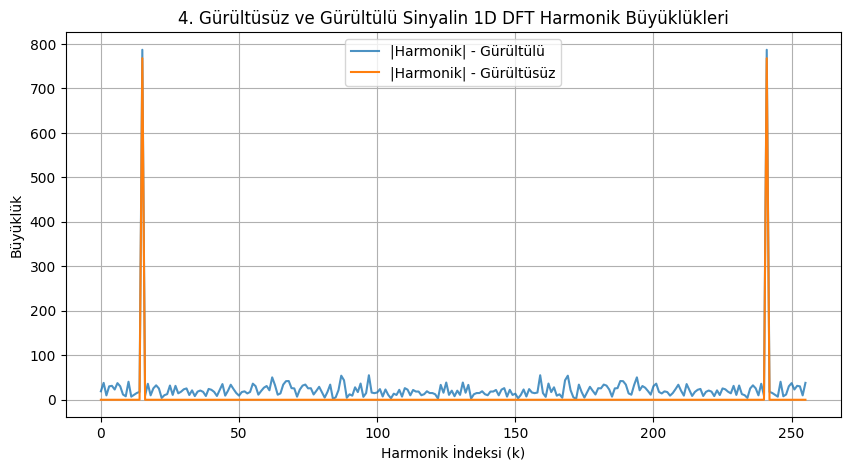

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def dft_1d(x):
    x = np.asarray(x, dtype=np.complex128)
    N = len(x)
    if N <= 0 or (N & (N - 1)) != 0:
        raise ValueError("Vektör uzunluğu 2'nin kuvveti olmalıdır.")

    n = np.arange(N, dtype=np.float64)
    k = n.reshape((N, 1))
    harmonik_matris = np.exp(-2j * np.pi * k * n / N)
    return harmonik_matris @ x


N = 256
fs = 256.0
t = np.arange(N) / fs
sinyal_temiz = 6.0 * np.sin(2 * np.pi * 15 * t)
sinyal_gurultulu = sinyal_temiz + np.random.default_rng(5).normal(0, 1.5, size=N)

harmonik_temiz = dft_1d(sinyal_temiz)
harmonik_gurultulu = dft_1d(sinyal_gurultulu)

plt.figure(figsize=(10, 5))
plt.plot(np.abs(harmonik_gurultulu), label="|Harmonik| - Gürültülü", alpha=0.8)
plt.plot(np.abs(harmonik_temiz), label="|Harmonik| - Gürültüsüz")
plt.title("4. Gürültüsüz ve Gürültülü Sinyalin 1D DFT Harmonik Büyüklükleri")
plt.xlabel("Harmonik İndeksi (k)")
plt.ylabel("Büyüklük")
plt.legend()
plt.grid(True)
plt.show()